# Siamese Network for Face Verification

This project uses the same `MyDataset` and `SiameseNetwork` classes and follows the structure of the original code.

The goal is to determine **whether two images belong to the same person**, rather than identifying who the person is.

The following settings were selected for this experiment:

- **Backbone:** EfficientNet-B0
- **Loss:** Contrastive Loss
- **Embedding size:** 256
- **Learning rate:** 0.0003
- **Batch size:** 32
- **Epochs:** 20
- **Training:** Freeze the backbone for the first 5 epochs, then unfreeze the last 4 blocks.

The label `1` indicates that two images belong to the same person, while `0` indicates different people. The decision threshold is determined using only the validation set.

In [25]:
import os

for root, dirs, files in os.walk('/kaggle/input'):
    print(root)
    if root.count('/') >= 5:
        dirs[:] = []

/kaggle/input
/kaggle/input/face-recognition-dataset-siamese-network
/kaggle/input/face-recognition-dataset-siamese-network/dataset
/kaggle/input/face-recognition-dataset-siamese-network/dataset/train
/kaggle/input/face-recognition-dataset-siamese-network/dataset/val


In [26]:
import os
import random
import io
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image, ImageOps
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix, precision_recall_curve
import matplotlib.pyplot as plt

try:
    from efficientnet_pytorch import EfficientNet
except ImportError:
   
    import sys
    import subprocess
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'efficientnet_pytorch'])
    from efficientnet_pytorch import EfficientNet

seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

data_root = '/kaggle/input/face-recognition-dataset-siamese-network/dataset'

train_root = os.path.join(data_root, 'train')
test_root = os.path.join(data_root, 'val')

feature_dim = 256
learning_rate = 3e-4
batch_size = 32
epochs = 20
freeze_epochs = 5
image_size = 224
margin = 1.0

if not os.path.isdir(train_root) or not os.path.isdir(test_root):
    raise FileNotFoundError('Dataset not found. Check train_root and test_root in Kaggle.')


Device: cuda


## 1. Image Preparation and Pair Generation

In `MyDataset`, similar to the original code, we select a second image for each image. During training, pairs are generated randomly, while Validation and Test pairs are fixed and balanced to make comparisons across different epochs more reliable.

For a positive pair, we need two **different image files** from the same class. If a class does not have enough images, no positive pairs are generated for that class.

In [27]:

image_extensions = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')


def read_images(root):
    images = []
    for cls in sorted(os.listdir(root)):
        folder = os.path.join(root, cls)
        if not os.path.isdir(folder):
            continue
        for img in sorted(os.listdir(folder)):
            path = os.path.join(folder, img)
            if os.path.isfile(path) and img.lower().endswith(image_extensions):
                images.append((path, cls))
    return images


def split_train_val(root, val_size=0.2):
    train_images = []
    val_images = []
    images = read_images(root)
    classes = sorted(set(cls for _, cls in images))

    for cls in classes:
        class_images = [img for img, label in images if label == cls]
        random.Random(seed).shuffle(class_images)
        if len(class_images) >= 4:
            n_val = max(2, round(len(class_images) * val_size))
            n_val = min(n_val, len(class_images) - 2)
            val_images.extend([(img, cls) for img in class_images[:n_val]])
            train_images.extend([(img, cls) for img in class_images[n_val:]])
        else:
            train_images.extend([(img, cls) for img in class_images])

    return train_images, val_images


class MyDataset(Dataset):
    def __init__(self, images, transform=None, fixed_pairs=False):
        self.images = images
        self.transform = transform
        self.fixed_pairs = fixed_pairs
        self.class_to_images = {}

        for img, cls in images:
            if cls not in self.class_to_images:
                self.class_to_images[cls] = []
            self.class_to_images[cls].append(img)

        self.classes = list(self.class_to_images.keys())
        self.positive_indices = [
            i for i, (img, cls) in enumerate(images)
            if len(self.class_to_images[cls]) > 1
        ]

        if len(self.classes) < 2:
            raise ValueError('At least two classes are needed to make negative pairs.')
        if len(self.positive_indices) == 0:
            raise ValueError('At least one class with two images is needed for positive pairs.')

        self.pairs = []
        if fixed_pairs:
            rng = random.Random(seed)
            for idx in self.positive_indices:
                self.pairs.append(self.make_pair(idx, True, rng))
                self.pairs.append(self.make_pair(idx, False, rng))

    def __len__(self):
        if self.fixed_pairs:
            return len(self.pairs)
        return len(self.images)

    def make_pair(self, idx, same, rng):
        img1, cls1 = self.images[idx]

        if same and len(self.class_to_images[cls1]) > 1:
            options = [img for img in self.class_to_images[cls1] if img != img1]
            img2 = rng.choice(options)
            label = 1
        else:
            cls2 = rng.choice([cls for cls in self.classes if cls != cls1])
            img2 = rng.choice(self.class_to_images[cls2])
            label = 0

        return img1, img2, label

    def __getitem__(self, idx):
        if self.fixed_pairs:
            img1, img2, label = self.pairs[idx]
        else:
            probability = random.random()
            same = probability < 0.5
            img1, img2, label = self.make_pair(idx, same, random)

        with Image.open(img1) as image1:
            img1 = image1.convert('RGB')
        with Image.open(img2) as image2:
            img2 = image2.convert('RGB')

        if self.transform:
            img1 = self.transform(img1)
            img2 = self.transform(img2)

        return img1, img2, label


train_images, val_images = split_train_val(train_root, val_size=0.2)
test_images = read_images(test_root)


train_transform = transforms.Compose([
    transforms.Resize((image_size, image_size)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(8),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


transform = transforms.Compose([
    transforms.Resize((image_size, image_size)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


train_dataset = MyDataset(train_images, transform=train_transform)
val_dataset = MyDataset(val_images, transform=transform, fixed_pairs=True)
test_pair_dataset = MyDataset(test_images, transform=transform, fixed_pairs=True)


train_loader = DataLoader(
    train_dataset, batch_size=batch_size, shuffle=True,
    num_workers=2, pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset, batch_size=batch_size, shuffle=False,
    num_workers=2, pin_memory=torch.cuda.is_available()
)

test_pair_loader = DataLoader(
    test_pair_dataset, batch_size=batch_size, shuffle=False,
    num_workers=2, pin_memory=torch.cuda.is_available()
)


class TestDataset(Dataset):
    def __init__(self, root, transform=None):
        self.test_images = read_images(root)
        self.transform = transform

    def __len__(self):
        return len(self.test_images)

    def __getitem__(self, idx):
        img, cls = self.test_images[idx]

        with Image.open(img) as image:
            img = image.convert('RGB')

        if self.transform:
            img = self.transform(img)

        return img, cls


test_dataset = TestDataset(test_root, transform=transform)

test_loader = DataLoader(
    test_dataset, batch_size=batch_size, shuffle=False,
    num_workers=2, pin_memory=torch.cuda.is_available()
)


print('Train images:', len(train_images))
print('Val images  :', len(val_images))
print('Test images :', len(test_images))
print('Val pairs   :', len(val_dataset))
print('Test pairs  :', len(test_pair_dataset))


Train images: 4893
Val images  : 1160
Test images : 918
Val pairs   : 2320
Test pairs  : 1836


## 2. Architecture and Loss Function

We use the same `SiameseNetwork` architecture with EfficientNet-B0 and a linear layer at the end. Each branch outputs a 256-dimensional embedding vector.

`ContrastiveLoss` brings embeddings of the same person closer together and pushes embeddings of different people farther apart.

Similar to the original code, the embedding vectors are normalized before calculating the distance.

In [28]:
class SiameseNetwork(nn.Module):
    def __init__(self, feature_dim=256, pretrained=True):
        super(SiameseNetwork, self).__init__()

        if pretrained:
            self.efficient = EfficientNet.from_pretrained('efficientnet-b0')
        else:
            self.efficient = EfficientNet.from_name('efficientnet-b0')
        self.efficient._fc = nn.Identity()

        self.fc = nn.Linear(
            self.efficient._conv_head.out_channels,
            feature_dim
        )
        self.relu = nn.ReLU()

    def forward_once(self, x):
        x = self.efficient.extract_features(x)
        x = F.adaptive_avg_pool2d(x, 1)
        x = x.view(x.size(0), -1)
        x = self.fc(x)
       
        return x

    def forward(self, input1, input2):
        out1 = self.forward_once(input1)
        out2 = self.forward_once(input2)
        return out1, out2


class ContrastiveLoss(nn.Module):
    def __init__(self, margin=1.0):
        super(ContrastiveLoss, self).__init__()
        self.margin = margin

    def forward(self, output1, output2, label):
        euclidean_distance = F.pairwise_distance(output1, output2)
        label = label.float()

        loss = torch.mean(
            label * torch.pow(euclidean_distance, 2) +
            (1 - label) * torch.pow(
                torch.clamp(self.margin - euclidean_distance, min=0.0), 2
            )
        )
        return loss


model = SiameseNetwork(feature_dim=feature_dim).to(device)
criterion = ContrastiveLoss(margin=margin)


Loaded pretrained weights for efficientnet-b0


## 2. Architecture and Loss Function

We use the same `SiameseNetwork` architecture with EfficientNet-B0 and a linear layer at the end. Each branch outputs a 256-dimensional embedding vector.

`ContrastiveLoss` brings embeddings of the same person closer together and pushes embeddings of different people farther apart.

Similar to the original code, the embedding vectors are normalized before calculating the distance.

In [29]:
def freeze_backbone(model):
    for param in model.efficient.parameters():
        param.requires_grad = False
    for param in model.fc.parameters():
        param.requires_grad = True


def unfreeze_last_blocks(model, last_blocks=4):
    for block in model.efficient._blocks[-last_blocks:]:
        for param in block.parameters():
            param.requires_grad = True
    for layer in [model.efficient._conv_head, model.efficient._bn1]:
        for param in layer.parameters():
            param.requires_grad = True


def run_epoch(model, loader, optimizer=None, fine_tuning=False):
    training = optimizer is not None

    if training:
        model.train()
        model.efficient.eval()
        if fine_tuning:
            for block in model.efficient._blocks[-4:]:
                block.train()
            model.efficient._bn1.train()
    else:
        model.eval()

    running_loss = 0.0
    total = 0

    with torch.set_grad_enabled(training):
        for img1, img2, label in loader:
            img1 = img1.to(device)
            img2 = img2.to(device)
            label = label.float().to(device)

            if training:
                optimizer.zero_grad()

            out1, out2 = model(img1, img2)
            out1 = F.normalize(out1, dim=1)
            out2 = F.normalize(out2, dim=1)
            loss = criterion(out1, out2, label)

            if training:
                loss.backward()
                optimizer.step()

            running_loss += loss.item() * len(label)
            total += len(label)

    return running_loss / total


freeze_backbone(model)
optimizer = torch.optim.Adam(model.fc.parameters(), lr=learning_rate)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.5)


In [30]:
train_losses = []
val_losses = []
best_val_loss = float('inf')
best_epoch = 0
best_path = '/kaggle/working/best_siamese_model.pth' if os.path.isdir('/kaggle/working') else 'best_siamese_model.pth'

for epoch in range(epochs):
    fine_tuning = epoch >= freeze_epochs

    if epoch == freeze_epochs:
        unfreeze_last_blocks(model, last_blocks=4)
        optimizer = torch.optim.Adam([
            {'params': model.fc.parameters(), 'lr': learning_rate},
            {'params': [p for p in model.efficient.parameters() if p.requires_grad],
             'lr': learning_rate / 10}
        ])
        scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.5)
        print('Last four EfficientNet blocks are unfrozen.')

    train_loss = run_epoch(model, train_loader, optimizer, fine_tuning=fine_tuning)
    val_loss = run_epoch(model, val_loader)

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    scheduler.step()

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_epoch = epoch + 1
        torch.save(model.state_dict(), best_path)

    print(f'Epoch [{epoch + 1}/{epochs}] - Train Loss: {train_loss:.4f} - Val Loss: {val_loss:.4f}')

print('Best epoch:', best_epoch)
print('Best validation loss:', round(best_val_loss, 4))
model.load_state_dict(torch.load(best_path, map_location=device, weights_only=True))
model.eval()


Epoch [1/20] - Train Loss: 0.1908 - Val Loss: 0.1748
Epoch [2/20] - Train Loss: 0.1698 - Val Loss: 0.1702
Epoch [3/20] - Train Loss: 0.1634 - Val Loss: 0.1640
Epoch [4/20] - Train Loss: 0.1570 - Val Loss: 0.1611
Epoch [5/20] - Train Loss: 0.1512 - Val Loss: 0.1594
Last four EfficientNet blocks are unfrozen.
Epoch [6/20] - Train Loss: 0.2312 - Val Loss: 0.1867
Epoch [7/20] - Train Loss: 0.1865 - Val Loss: 0.1740
Epoch [8/20] - Train Loss: 0.1751 - Val Loss: 0.1650
Epoch [9/20] - Train Loss: 0.1623 - Val Loss: 0.1579
Epoch [10/20] - Train Loss: 0.1546 - Val Loss: 0.1510
Epoch [11/20] - Train Loss: 0.1475 - Val Loss: 0.1475
Epoch [12/20] - Train Loss: 0.1466 - Val Loss: 0.1453
Epoch [13/20] - Train Loss: 0.1418 - Val Loss: 0.1446
Epoch [14/20] - Train Loss: 0.1405 - Val Loss: 0.1418
Epoch [15/20] - Train Loss: 0.1384 - Val Loss: 0.1415
Epoch [16/20] - Train Loss: 0.1348 - Val Loss: 0.1402
Epoch [17/20] - Train Loss: 0.1332 - Val Loss: 0.1400
Epoch [18/20] - Train Loss: 0.1289 - Val Loss: 

SiameseNetwork(
  (efficient): EfficientNet(
    (_conv_stem): Conv2dStaticSamePadding(
      3, 32, kernel_size=(3, 3), stride=(2, 2), bias=False
      (static_padding): ZeroPad2d((0, 1, 0, 1))
    )
    (_bn0): BatchNorm2d(32, eps=0.001, momentum=0.010000000000000009, affine=True, track_running_stats=True)
    (_blocks): ModuleList(
      (0): MBConvBlock(
        (_depthwise_conv): Conv2dStaticSamePadding(
          32, 32, kernel_size=(3, 3), stride=[1, 1], groups=32, bias=False
          (static_padding): ZeroPad2d((1, 1, 1, 1))
        )
        (_bn1): BatchNorm2d(32, eps=0.001, momentum=0.010000000000000009, affine=True, track_running_stats=True)
        (_se_reduce): Conv2dStaticSamePadding(
          32, 8, kernel_size=(1, 1), stride=(1, 1)
          (static_padding): Identity()
        )
        (_se_expand): Conv2dStaticSamePadding(
          8, 32, kernel_size=(1, 1), stride=(1, 1)
          (static_padding): Identity()
        )
        (_project_conv): Conv2dStaticSamePa

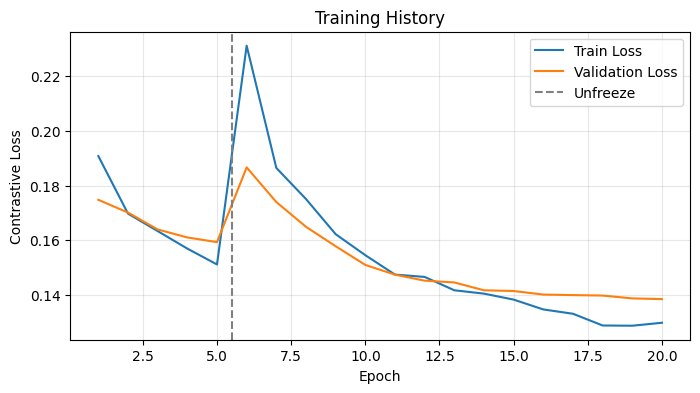

In [39]:
plt.figure(figsize=(8, 4))
plt.plot(range(1, epochs + 1), train_losses, label='Train Loss')
plt.plot(range(1, epochs + 1), val_losses, label='Validation Loss')
plt.axvline(freeze_epochs + 0.5, linestyle='--', color='gray', label='Unfreeze')
plt.xlabel('Epoch')
plt.ylabel('Contrastive Loss')
plt.title('Training History')
threshold = 1.10
plt.legend()
plt.grid(alpha=0.3)
plt.show()


## 4. Selecting the Threshold Using Validation

For two images of the same person, we expect a **smaller distance** between their embeddings.

We select the threshold that gives the highest F1 score on the Validation pairs. The Test set is not used for threshold tuning.

In [32]:
def get_distances(model, loader):
    model.eval()
    distances = []
    labels = []

    with torch.no_grad():
        for img1, img2, label in loader:
            img1 = img1.to(device)
            img2 = img2.to(device)

            out1, out2 = model(img1, img2)
            out1 = F.normalize(out1, dim=1)
            out2 = F.normalize(out2, dim=1)
            distance = F.pairwise_distance(out1, out2)

            distances.extend(distance.cpu().numpy())
            labels.extend(label.numpy())

    return np.array(distances), np.array(labels)


val_distances, val_labels = get_distances(model, val_loader)

# With a negative distance as the score, higher means more similar.
precision, recall, score_thresholds = precision_recall_curve(val_labels, -val_distances)
val_f1 = 2 * precision[:-1] * recall[:-1] / (precision[:-1] + recall[:-1] + 1e-8)
best_idx = int(np.argmax(val_f1))
threshold = float(-score_thresholds[best_idx])

print('Threshold from validation:', round(threshold, 4))
print('Validation F1:', round(f1_score(val_labels, (val_distances <= threshold).astype(int)), 4))


Threshold from validation: 0.5277
Validation F1: 0.8358


## 5. Final Evaluation on the Test Set

These evaluation metrics measure the model's performance in **comparing two images**, not identifying a person's name or identity.

If the Train and Test sets contain images of the same people, we cannot assume that the model will achieve the same performance on completely unseen identities.

Accuracy : 0.8088
Precision: 0.7902
Recall   : 0.841
F1 Score : 0.8148
ROC AUC  : 0.8945


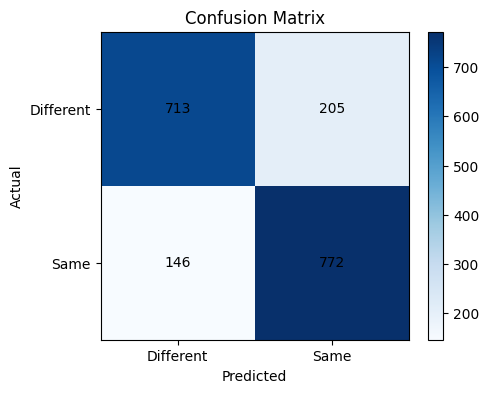

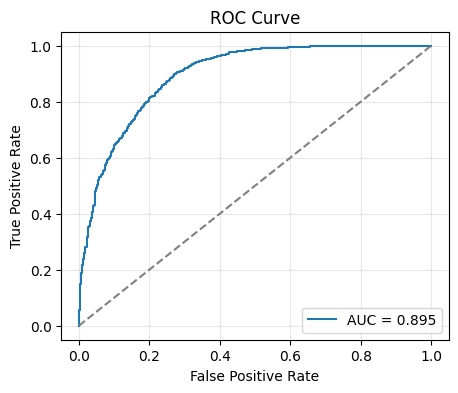

In [33]:
test_distances, test_labels = get_distances(model, test_pair_loader)
test_predictions = (test_distances <= threshold).astype(int)

print('Accuracy :', round(accuracy_score(test_labels, test_predictions), 4))
print('Precision:', round(precision_score(test_labels, test_predictions, zero_division=0), 4))
print('Recall   :', round(recall_score(test_labels, test_predictions, zero_division=0), 4))
print('F1 Score :', round(f1_score(test_labels, test_predictions, zero_division=0), 4))

if len(np.unique(test_labels)) == 2:
    auc = roc_auc_score(test_labels, -test_distances)
    print('ROC AUC  :', round(auc, 4))
else:
    print('ROC AUC  : undefined (only one label in test pairs)')

cm = confusion_matrix(test_labels, test_predictions, labels=[0, 1])
plt.figure(figsize=(5, 4))
plt.imshow(cm, cmap='Blues')
for i in range(2):
    for j in range(2):
        plt.text(j, i, str(cm[i, j]), ha='center', va='center')
plt.xticks([0, 1], ['Different', 'Same'])
plt.yticks([0, 1], ['Different', 'Same'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.colorbar()
plt.show()

if len(np.unique(test_labels)) == 2:
    fpr, tpr, _ = roc_curve(test_labels, -test_distances)
    plt.figure(figsize=(5, 4))
    plt.plot(fpr, tpr, label=f'AUC = {auc:.3f}')
    plt.plot([0, 1], [0, 1], '--', color='gray')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('ROC Curve')
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()


## 6. Extracting Embeddings from Test Images

This section continues from the last cell of the original notebook. We use `forward_once` to extract the embedding vector of each image separately.

In [34]:
model.eval()

all_embeddings = []
all_labels = []

with torch.no_grad():
    for img, cls in test_loader:
        img = img.to(device)

        emb = model.forward_once(img)
        emb = F.normalize(emb, dim=1)

        all_embeddings.append(emb.cpu())
        all_labels.extend(cls)

all_embeddings = torch.cat(all_embeddings, dim=0)
print('Test embedding shape:', tuple(all_embeddings.shape))

checkpoint = {
    'model_state_dict': model.state_dict(),
    'feature_dim': feature_dim,
    'image_size': image_size,
    'threshold': threshold,
    'best_epoch': best_epoch,
    'validation_loss': best_val_loss
}
checkpoint_path = '/kaggle/working/siamese_checkpoint.pth' if os.path.isdir('/kaggle/working') else 'siamese_checkpoint.pth'
torch.save(checkpoint, checkpoint_path)
print('Checkpoint saved:', checkpoint_path)


Test embedding shape: (918, 256)
Checkpoint saved: /kaggle/working/siamese_checkpoint.pth


## 7. Testing Two Images with the Model

The `compare_faces` function takes two images and compares the distance between their embeddings with the threshold obtained from Validation. The inputs can be either file paths or `PIL` images.

**Note:** This project does not include automatic face detection or cropping. For better results, each image should contain one clear face, preferably near the center. The output is the model's prediction, not definitive proof of identity.

To use the model again without retraining, we can load the saved model and threshold from `siamese_checkpoint.pth` using the `load_saved_model` function.

In [35]:
def load_saved_model(path):
    saved = torch.load(path, map_location=device, weights_only=True)
    saved_model = SiameseNetwork(feature_dim=saved['feature_dim'], pretrained=False).to(device)
    saved_model.load_state_dict(saved['model_state_dict'])
    saved_model.eval()
    return saved_model, float(saved['threshold'])





def compare_faces(img1, img2):
    if isinstance(img1, (str, os.PathLike)):
        with Image.open(img1) as image:
            img1 = ImageOps.exif_transpose(image).convert('RGB')
    else:
        img1 = ImageOps.exif_transpose(img1).convert('RGB')

    if isinstance(img2, (str, os.PathLike)):
        with Image.open(img2) as image:
            img2 = ImageOps.exif_transpose(image).convert('RGB')
    else:
        img2 = ImageOps.exif_transpose(img2).convert('RGB')

    img1 = transform(img1).unsqueeze(0).to(device)
    img2 = transform(img2).unsqueeze(0).to(device)

    model.eval()
    with torch.no_grad():
        out1, out2 = model(img1, img2)
        out1 = F.normalize(out1, dim=1)
        out2 = F.normalize(out2, dim=1)
        distance = F.pairwise_distance(out1, out2).item()

    same_person = distance <= threshold
    return same_person, distance



## 8. GUI for Comparing Two Images

Upload two images and click **Compare Faces**. The result, the distance between the two images, and the selected threshold will be displayed.

The GUI is built using `ipywidgets` directly inside the notebook, so the images are not uploaded to a public website.

Run this section **after training the model and calculating the threshold**.

To test a new pair of images, simply replace the uploaded images and click the button again.

In [36]:
try:
    import ipywidgets as widgets
except ImportError:
    import sys
    import subprocess
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'ipywidgets'])
    import ipywidgets as widgets
from IPython.display import display


def get_uploaded_image(uploader):
    uploaded = uploader.value
    if not uploaded:
        raise ValueError('Please upload both images.')

    if isinstance(uploaded, dict):
        file_data = next(iter(uploaded.values()))
    else:
        file_data = uploaded[0]

    return Image.open(io.BytesIO(bytes(file_data['content']))).convert('RGB')


upload1 = widgets.FileUpload(accept='image/*', multiple=False, description='First image')
upload2 = widgets.FileUpload(accept='image/*', multiple=False, description='Second image')
compare_button = widgets.Button(description='Compare Faces', button_style='primary', icon='check')
result_box = widgets.Output()


def on_compare_clicked(button):
    with result_box:
        result_box.clear_output(wait=True)
        try:
            image1 = get_uploaded_image(upload1)
            image2 = get_uploaded_image(upload2)

            display(widgets.HBox([
                widgets.VBox([widgets.HTML('<b>Image 1</b>'),
                              widgets.Image(value=make_preview(image1), format='png', width=200)]),
                widgets.VBox([widgets.HTML('<b>Image 2</b>'),
                              widgets.Image(value=make_preview(image2), format='png', width=200)])
            ]))

            same, distance = compare_faces(image1, image2)
            if same:
                print('Result: SAME PERSON')
            else:
                print('Result: DIFFERENT PEOPLE')

            print(f'Distance: {distance:.4f}')
            print(f'Threshold: {threshold:.4f}')
        except Exception as error:
            print('Error:', error)


def make_preview(image):
    preview = ImageOps.contain(image, (200, 200))
    buffer = io.BytesIO()
    preview.save(buffer, format='PNG')
    return buffer.getvalue()


compare_button.on_click(on_compare_clicked)
display(widgets.VBox([
    widgets.HTML('<h3>Face Verification</h3><p>Upload two face photos and compare them.</p>'),
    widgets.HBox([upload1, upload2]),
    compare_button,
    result_box
]))


### Notes on Interpreting the Results

- Validation and Test pairs are generated using fixed random seeds. For each eligible image, we create one positive pair and one negative pair. The number of images or pairs alone does not determine the quality of the experiment.
- Train and Validation sets are split at the **image level**, not the **identity level**. To evaluate the model on unseen identities, we need to split the data by person.
- The Test set is not used for selecting the threshold or model weights.
- For an accurate report, only include Loss, Accuracy, and ROC-AUC values after actually running the notebook in Kaggle.
- During the first run, you may need to enable Internet access in Kaggle to download the pretrained EfficientNet weights and install `efficientnet_pytorch` if necessary.
- The GUI result is not a calibrated probability or a guarantee of identity. If an image contains no face or multiple faces, the prediction may not be reliable.